# FGM Data Preparation and EDA, Kenya, all survey rounds (V2)

This notebook harmonizes every Kenya DHS round with an FGM module into one consistent dataset,
then describes it. It replaces the single-round (DHS 2022) preparation used in V1. Kenya has no
national MICS; its MICS surveys cover single areas (Mombasa informal settlements 2009, Nyanza
2011, Bungoma, Kakamega and Turkana 2013–14) and are compared separately, not pooled.

| Survey | Women: own status | Women: age at cutting | Daughters | Women's attitude | Men's attitude |
|---|---|---|---|---|---|
| DHS 1998 | yes (asked of all; no "heard of FGM" question) | yes | eldest daughter only (not used) | yes (no "depends") | not asked |
| DHS 2003 | yes (asked of all) | not asked | eldest daughter only (not used) | not asked | men's file not available |
| DHS 2008–09 | yes | yes | most recently cut daughter only | yes | not asked |
| DHS 2014 | yes (long-questionnaire subsample) | yes | full roster (0–14) | yes | yes |
| DHS 2022 | yes (long-questionnaire subsample) | yes | full roster (0–14) | yes | yes |

Definitions corrected relative to V1:

1. **"During infancy" is spread over early childhood.** DHS code 95 ("during infancy",
   available in DHS 2008–09, 2014 and 2022) is spread over ages 0–4, in proportion to the ages
   reported by women of the same survey and birth cohort who gave an exact age. DHS 1998 has
   no infancy code. Few Kenyan women give this answer, because most were cut after infancy.
2. **Never-heard women are not cut.** Women who have never heard of FGM are not asked the
   status question. Following DHS convention, they and their daughters aged 0–14 are counted
   as not cut (daughters added from the birth history). DHS 1998 and 2003 asked every woman
   her status directly, without a "heard of FGM" question.
3. **Unknown ages are estimated; unknown status is excluded.** When a cut woman or daughter
   has a "don't know", missing or inconsistent age at cutting, the case is spread over ages 0
   to her current age, using exact-age reporters from the same survey and cohort (or the
   whole survey if the cohort has fewer than 30). No cut case is dropped. Women who don't
   know whether they were cut are excluded. Sections 4–6 report the counts, and section 7.1
   shows how ages are estimated.

Weights are rescaled to mean one within each survey, so pooled analyses weight each
round by its sample size; each survey keeps its own clusters and strata. In DHS 2014 and 2022
the FGM questions were asked only in the long-questionnaire subsample (about half of women);
women outside it have no FGM data and are not counted.

## 0. Configuration

In [1]:
country_name <- "Kenya"
country_iso3 <- "KEN"

project_root <- if (dir.exists("../02_Data")) ".." else "."
processed_dir <- file.path(project_root, "02_Data", "processed", country_iso3)
harmonized_dir <- file.path(processed_dir, "harmonized")
analysis_dir <- file.path(processed_dir, "analysis")
output_dir <- file.path(project_root, "03_Outputs", country_iso3, "EDA")
for (d in c(harmonized_dir, analysis_dir, output_dir)) dir.create(d, recursive = TRUE, showWarnings = FALSE)

options(repr.plot.width = 13, repr.plot.height = 7, width = 200)

## 1. Setup and survey inventory

In [2]:
# Kenya has no national MICS; its MICS surveys are subnational and are compared separately
# (mics_core.R), not pooled here.
suppressPackageStartupMessages({
  library(tidyverse)
  library(haven)
})

raw_dir <- file.path(project_root, "02_Data", "raw")
ext_dir <- file.path(raw_dir, "kenya_FGM_Data", "extracted", "DHS")

max_age_years    <- 49
max_daughter_age <- 14
cohort_breaks    <- seq(1945, 2025, by = 5)
cohort_labels    <- paste0(head(cohort_breaks, -1), " to ", head(cohort_breaks, -1) + 4)

# Pooled analyses use the 8 former provinces (available in every round). DHS 2022 records
# only the 47 counties, which are mapped to their former province; 2014 and 2022 also keep the
# county for county-level estimates. DHS 1998 did not sample North Eastern province.
kenya_provinces <- c("CENTRAL", "COAST", "EASTERN", "NAIROBI", "NORTH EASTERN", "NYANZA", "RIFT VALLEY", "WESTERN")
county_to_province <- c(
  "MOMBASA"="COAST","KWALE"="COAST","KILIFI"="COAST","TANA RIVER"="COAST","LAMU"="COAST","TAITA TAVETA"="COAST",
  "GARISSA"="NORTH EASTERN","WAJIR"="NORTH EASTERN","MANDERA"="NORTH EASTERN",
  "MARSABIT"="EASTERN","ISIOLO"="EASTERN","MERU"="EASTERN","THARAKA NITHI"="EASTERN","EMBU"="EASTERN","KITUI"="EASTERN",
  "MACHAKOS"="EASTERN","MAKUENI"="EASTERN",
  "NYANDARUA"="CENTRAL","NYERI"="CENTRAL","KIRINYAGA"="CENTRAL","MURANG A"="CENTRAL","KIAMBU"="CENTRAL",
  "TURKANA"="RIFT VALLEY","WEST POKOT"="RIFT VALLEY","SAMBURU"="RIFT VALLEY","TRANS NZOIA"="RIFT VALLEY",
  "UASIN GISHU"="RIFT VALLEY","ELGEYO MARAKWET"="RIFT VALLEY","NANDI"="RIFT VALLEY","BARINGO"="RIFT VALLEY",
  "LAIKIPIA"="RIFT VALLEY","NAKURU"="RIFT VALLEY","NAROK"="RIFT VALLEY","KAJIADO"="RIFT VALLEY","KERICHO"="RIFT VALLEY",
  "BOMET"="RIFT VALLEY",
  "KAKAMEGA"="WESTERN","VIHIGA"="WESTERN","BUNGOMA"="WESTERN","BUSIA"="WESTERN",
  "SIAYA"="NYANZA","KISUMU"="NYANZA","HOMA BAY"="NYANZA","MIGORI"="NYANZA","KISII"="NYANZA","NYAMIRA"="NYANZA",
  "NAIROBI"="NAIROBI")
kenya_counties <- sort(names(county_to_province))


# Men were asked about FGM only in DHS 2014 and 2022 (no FGM questions for men in 1998 or
# 2008-09; the 2003 men's file is not available).
rounds <- tribble(
  ~survey_id,  ~survey_type, ~round_year, ~ir_file,                  ~mr_file,
  "DHS 1998",  "DHS",        1998,        "KEIR3ADT/KEIR3AFL.DTA",   NA,
  "DHS 2003",  "DHS",        2003,        "KEIR42DT/KEIR42FL.DTA",   NA,
  "DHS 2008",  "DHS",        2008,        "KEIR52DT/KEIR52FL.DTA",   NA,
  "DHS 2014",  "DHS",        2014,        "KEIR72DT/KEIR72FL.DTA",   "KE_2014_DHS_10142026_516_258683/KEMR72DT/KEMR72FL.DTA",
  "DHS 2022",  "DHS",        2022,        "KEIR8CDT/KEIR8CFL.DTA",   "KE_2022_DHS_10142026_513_258683/KEMR8CDT/KEMR8CFL.DTA"
)


rounds |> dplyr::mutate(women_file = basename(ir_file), men_file = basename(mr_file)) |>
  dplyr::select(survey_id, survey_type, round_year, women_file, men_file)

survey_id,survey_type,round_year,women_file,men_file
<chr>,<chr>,<dbl>,<chr>,<chr>
DHS 1998,DHS,1998,KEIR3AFL.DTA,NA
DHS 2003,DHS,2003,KEIR42FL.DTA,NA
DHS 2008,DHS,2008,KEIR52FL.DTA,NA
DHS 2014,DHS,2014,KEIR72FL.DTA,KEMR72FL.DTA
DHS 2022,DHS,2022,KEIR8CFL.DTA,KEMR8CFL.DTA


## 2. Harmonization rules

Shared coding applied to every round: the 8 former provinces (DHS 2022 records only counties,
which are mapped to their former province; DHS 1998 did not sample North Eastern), the 47
counties for DHS 2014 and 2022, ethnicity grouped into the ten large groups coded in every round
plus "other", religion, education and wealth collapsed to categories every survey can supply,
and age at cutting coded with infancy as age 0.

In [3]:
lbl <- function(x) tolower(trimws(as.character(haven::as_factor(x))))
num <- function(x) as.numeric(haven::zap_labels(x))
pick_col <- function(d, v) if (v %in% names(d)) d[[v]] else rep(NA, nrow(d))

clean_name <- function(x) toupper(as.character(x)) |> str_replace_all("[^A-Z ]", " ") |> str_squish()
standardize_region <- function(x) {          # former province
  s <- clean_name(x)
  s <- case_when(s == "NORTHEASTERN" ~ "NORTH EASTERN", TRUE ~ s)
  bad <- setdiff(unique(s[!is.na(s)]), kenya_provinces)
  if (length(bad)) stop("Unmatched province names: ", paste(bad, collapse = ", "))
  s
}
standardize_county <- function(x) {
  s <- clean_name(x)
  s <- case_when(s == "ELGEYO MARAKWET" | s == "KEIYO MARAKWET" ~ "ELGEYO MARAKWET", s == "THARAKA" ~ "THARAKA NITHI", TRUE ~ s)
  bad <- setdiff(unique(s[!is.na(s)]), kenya_counties)
  if (length(bad)) stop("Unmatched county names: ", paste(bad, collapse = ", "))
  s
}
province_from_county <- function(county) unname(county_to_province[county])

# Ten large groups coded in every round, everything else "other" (Turkana, Kuria, Samburu,
# Taita/Taveta and smaller groups are not coded separately in every round).
harmonize_ethnicity <- function(x) {
  x <- tolower(as.character(x))
  case_when(
    is.na(x) | str_detect(x, "^(missing|dk|don.t know)$") ~ NA_character_,
    str_detect(x, "kikuy") ~ "kikuyu",
    str_detect(x, "luhya") ~ "luhya",
    str_detect(x, "kalenjin") ~ "kalenjin",
    str_detect(x, "^luo") ~ "luo",
    str_detect(x, "kamba") ~ "kamba",
    str_detect(x, "kisii") ~ "kisii",
    str_detect(x, "meru|embu") ~ "meru/embu",
    str_detect(x, "mijikenda|swahili") ~ "mijikenda/swahili",
    str_detect(x, "somali") ~ "somali",
    str_detect(x, "masai|maasai") ~ "maasai",
    TRUE ~ "other"
  )
}

harmonize_religion <- function(x) {
  x <- tolower(as.character(x))
  case_when(
    is.na(x) | str_detect(x, "missing|manquant|^dk|nsp") ~ NA_character_,
    str_detect(x, "islam|muslim|moslem|musulman") ~ "islam",
    str_detect(x, "catholi|protestan|christian|evangel|instituted|orthodox|church") ~ "christian",
    str_detect(x, "tradition") ~ "traditional",
    TRUE ~ "other/none"
  )
}

harmonize_education <- function(x) {
  x <- tolower(as.character(x))
  case_when(
    is.na(x) | str_detect(x, "missing|manquant|dk|don.t know") ~ NA_character_,
    str_detect(x, "^no|none|non-formal|non formal|pre-?school") ~ "none",
    str_detect(x, "primary") ~ "primary",
    str_detect(x, "secondary|higher|tertiary") ~ "secondary or higher",
    TRUE ~ NA_character_
  )
}

harmonize_wealth <- function(x) {
  v <- num(x)
  factor(if_else(v %in% 1:5, v, NA_real_), levels = 1:5,
         labels = c("poorest", "poorer", "middle", "richer", "richest")) |> as.character()
}

# Age-at-cutting coding shared by all rounds: returns the usable age (infancy = 0)
# and a reporting category for the EDA.
code_age_at_cut <- function(raw, infancy_code = 95, max_valid) {
  cat_ <- case_when(
    is.na(raw) ~ "missing",
    raw == infancy_code ~ "during infancy",
    raw == 0 ~ "age 0",
    raw >= 0 & raw <= max_valid ~ "specific age 1+",
    raw == 98 ~ "don't know",
    raw == 97 ~ "inconsistent",
    TRUE ~ "missing"
  )
  age <- case_when(raw == infancy_code ~ 0, raw >= 0 & raw <= max_valid ~ raw, TRUE ~ NA_real_)
  list(age = age, category = cat_)
}

to_cohort <- function(birth_year) {
  as.character(cut(birth_year, breaks = cohort_breaks, right = FALSE, labels = cohort_labels))
}

attitude_from <- function(x) {
  v <- num(x)
  case_when(v == 1 ~ 1L, v == 2 ~ 0L, TRUE ~ NA_integer_)
}
attitude_label <- function(x) {
  v <- num(x)
  case_when(v == 1 ~ "continued", v == 2 ~ "stopped", v == 3 ~ "depends",
            v == 8 ~ "don't know", TRUE ~ NA_character_)
}

### 2.1 DHS loader

Own status uses `s1002` (1998), `s821` (2003) and `g102` (2008–09, 2014, 2022). From 2008–09,
women who never heard of FGM (`g100` = no and `g101` = no) are not cut. Age at cutting uses
`s1003` (1998) and `g106`; DHS 2003 did not ask it. Attitude uses `s1012` (1998) and `g119`.
Daughters come from the full roster (2014, 2022); daughters 0–14 of never-heard mothers are
added from the birth history as not cut.

In [4]:
load_dhs_round <- function(survey_id, round_year, ir_file) {
  path <- file.path(ext_dir, ir_file)
  # DHS 1998 and 2003 used country-specific questions (s10xx, s82x) and had no "heard of FGM"
  # question: every woman was asked her own status. DHS 2003 asked status only (no age at
  # cutting, no attitude). DHS 2008-09 recorded the most recently cut daughter only; DHS 2014
  # and 2022 list every daughter. In 2014 and 2022 the FGM questions were asked only in the
  # long-questionnaire subsample (women outside it have no FGM data).
  fg <- switch(as.character(round_year),
    "1998" = list(heard = NA, probe = NA, status = "s1002", age = "s1003", attitude = "s1012", recent_age = NA),
    "2003" = list(heard = NA, probe = NA, status = "s821", age = NA, attitude = NA, recent_age = NA),
    "2008" = list(heard = "g100", probe = "g101", status = "g102", age = "g106", attitude = "g119", recent_age = "g113"),
    list(heard = "g100", probe = "g101", status = "g102", age = "g106", attitude = "g119", recent_age = NA))
  keep <- c("v001", "v002", "v003", "v005", "v007", "v010", "v012", "v021", "v022", "v024", "v025",
            "v106", "v130", "v131", "v190", "scounty", unlist(fg))
  ir <- read_dta(path, col_select = c(any_of(keep[!is.na(keep)]),
                                      matches("^(gidx|g121|g122|bidx|b2|b4|b5|b8)_[0-9]{2}$")))
  col <- function(v) if (!is.na(v) && v %in% names(ir)) num(ir[[v]]) else rep(NA_real_, nrow(ir))

  heard <- col(fg$heard); probe <- col(fg$probe); status_raw <- col(fg$status)
  status_raw[!status_raw %in% c(0, 1, 8)] <- NA
  if (is.na(fg$heard)) {
    module_asked <- !is.na(status_raw)
    never_heard <- rep(FALSE, nrow(ir))
  } else {
    module_asked <- !is.na(heard) & heard %in% c(0, 1)
    never_heard <- module_asked & heard == 0 & (is.na(probe) | probe == 0)
  }
  fgm_status <- case_when(status_raw == 1 ~ 1L, status_raw == 0 ~ 0L, never_heard ~ 0L, TRUE ~ NA_integer_)
  age_raw <- col(fg$age)
  age_code <- code_age_at_cut(age_raw, infancy_code = 95, max_valid = max_age_years)
  # Province and county: 1998-2008 provinces only; 2014 province (v024) and county (scounty);
  # 2022 county only (v024), mapped to its former province.
  county <- if (round_year == 2014) standardize_county(lbl(ir$scounty)) else if (round_year == 2022) standardize_county(lbl(ir$v024)) else NA_character_
  region <- if (round_year == 2022) province_from_county(county) else standardize_region(lbl(ir$v024))
  century <- if (round_year == 1998) 1900 else 0       # DHS 1998 stores two-digit years
  attitude_raw <- if (is.na(fg$attitude)) rep(NA_real_, nrow(ir)) else ir[[fg$attitude]]

  women <- tibble(
    survey_id, survey_type = "DHS", round_year,
    resp_id = paste(survey_id, ir$v001, ir$v002, ir$v003, sep = "-"),
    cluster = paste(survey_id, ir$v001, sep = "-"),
    strata = paste(survey_id, num(ir$v022)),
    weight_raw = num(ir$v005) / 1e6,
    region, county,
    urban_rural = lbl(ir$v025),
    age = num(ir$v012),
    interview_year = num(ir$v007) + century,
    birth_year = num(ir$v010) + century,
    education = harmonize_education(lbl(ir$v106)),
    religion = harmonize_religion(lbl(ir$v130)),
    ethnicity = harmonize_ethnicity(lbl(ir$v131)),
    wealth = harmonize_wealth(pick_col(ir, "v190")),
    module_asked,
    fgm_heard = if (is.na(fg$heard)) NA else (!never_heard & module_asked),
    status_reported = case_when(status_raw %in% c(0, 1) ~ "asked",
                                never_heard ~ "never heard (uncut)",
                                status_raw == 8 ~ "don't know",
                                module_asked ~ "missing",
                                TRUE ~ "module not asked"),
    fgm_status,
    fgm_age_raw = age_raw,
    fgm_age = if_else(fgm_status == 1, age_code$age, NA_real_),
    age_report = case_when(is.na(fgm_status) | fgm_status != 1 ~ NA_character_,
                           is.na(fg$age) ~ "not asked in survey",
                           TRUE ~ age_code$category),
    attitude_answer = attitude_label(attitude_raw),
    supports_continuation = attitude_from(attitude_raw)
  )

  # Most recently cut daughter only (DHS 2008-09): descriptive use.
  recent <- tibble()
  if (!is.na(fg$recent_age) && fg$recent_age %in% names(ir)) {
    ra <- num(ir[[fg$recent_age]])
    rc <- code_age_at_cut(ra, infancy_code = 95, max_valid = max_daughter_age)
    recent <- tibble(survey_id, survey_type = "DHS", round_year, resp_id = women$resp_id,
                     weight_raw = women$weight_raw, region = women$region,
                     daughter_age_at_cut = rc$age, age_report = rc$category) |>
      filter(!is.na(ra))
  }

  # Full daughter roster (DHS 2014, 2022) plus daughters of never-heard mothers.
  daughters <- tibble()
  if (any(str_detect(names(ir), "^gidx_01$"))) {
    roster <- ir |>
      transmute(resp_id = women$resp_id, across(matches("^(gidx|g121|g122)_[0-9]{2}$"), num)) |>
      pivot_longer(-resp_id, names_to = c(".value", "slot"), names_pattern = "^(gidx|g121|g122)_([0-9]{2})$") |>
      filter(!is.na(gidx)) |>
      transmute(resp_id, birth_order = as.integer(gidx),
                daughter_status = case_when(g121 == 1 ~ 1L, g121 == 0 ~ 0L, TRUE ~ NA_integer_),
                age_at_cut_raw = g122)
    births <- ir |>
      transmute(resp_id = women$resp_id, across(matches("^(bidx|b2|b4|b5|b8)_[0-9]{2}$"), num)) |>
      pivot_longer(-resp_id, names_to = c(".value", "slot"), names_pattern = "^(bidx|b2|b4|b5|b8)_([0-9]{2})$") |>
      filter(!is.na(bidx), b4 == 2, b5 == 1, !is.na(b8), b8 <= max_daughter_age) |>
      transmute(resp_id, birth_order = as.integer(bidx), daughter_age = b8, birth_year = b2)
    reported <- births |> inner_join(roster, by = c("resp_id", "birth_order")) |>
      filter(!is.na(daughter_status)) |> mutate(source = "roster")
    imputed <- births |>
      semi_join(women |> filter(status_reported == "never heard (uncut)"), by = "resp_id") |>
      anti_join(reported, by = c("resp_id", "birth_order")) |>
      mutate(daughter_status = 0L, age_at_cut_raw = NA_real_, source = "mother never heard (uncut)")
    daughters <- bind_rows(reported, imputed) |>
      mutate(survey_id, survey_type = "DHS", round_year,
             daughter_id = paste(resp_id, birth_order, sep = "-d"))
  }
  list(women = women, daughters = daughters, recent = recent)
}

### 2.2 DHS men loader (DHS 2014 and 2022)

In [5]:
load_dhs_men <- function(survey_id, round_year, mr_file) {
  mr <- read_dta(file.path(ext_dir, mr_file))
  county <- if (round_year == 2014) standardize_county(lbl(mr$smcounty)) else standardize_county(lbl(mr$mv024))
  region <- if (round_year == 2014) standardize_region(lbl(mr$mv024)) else province_from_county(county)
  heard <- num(mr$mg100); probe <- num(mr$mg101)
  tibble(
    survey_id, survey_type = "DHS", round_year,
    resp_id = paste(survey_id, mr$mv001, mr$mv002, mr$mv003, "m", sep = "-"),
    cluster = paste(survey_id, mr$mv001, sep = "-"),
    strata = paste(survey_id, num(mr$mv022)),
    weight_raw = num(mr$mv005) / 1e6,
    region, county,
    urban_rural = lbl(mr$mv025),
    age = num(mr$mv012),
    education = harmonize_education(lbl(mr$mv106)),
    religion = harmonize_religion(lbl(mr$mv130)),
    ethnicity = harmonize_ethnicity(lbl(mr$mv131)),
    wealth = harmonize_wealth(pick_col(mr, "mv190")),
    fgm_heard = heard %in% 1 | probe %in% 1,
    attitude_answer = attitude_label(mr$mg119),
    supports_continuation = attitude_from(mr$mg119)
  ) |>
    filter(age >= 15, age <= max_age_years, !is.na(heard))
}

### 2.3 Harmonize all rounds

In [6]:
# Automatic coverage check, run for every round with a daughter list. DHS and MICS daughter
# lists cover only mothers who have heard of FGM, so the daughters of never-heard mothers must be
# added (as not cut) from the birth history or household roster. Stop if a round has never-heard
# women but no such daughters; warn if their share of daughters is far below their share of women.
check_daughter_coverage <- function(women, daughters) {
  chk <- women |>
    group_by(survey_id) |>
    summarise(women = n(), never_heard_women = sum(status_reported == "never heard (uncut)", na.rm = TRUE), .groups = "drop") |>
    inner_join(daughters |> group_by(survey_id) |>
                 summarise(daughters = n(), daughters_of_never_heard = sum(source == "mother never heard (uncut)"), .groups = "drop"),
               by = "survey_id") |>
    mutate(pct_never_heard_women = round(100 * never_heard_women / women, 1),
           pct_daughters_of_never_heard = round(100 * daughters_of_never_heard / daughters, 1))
  print(as.data.frame(chk))
  missing <- chk |> filter(never_heard_women > 0, daughters_of_never_heard == 0)
  if (nrow(missing)) stop("Daughters of never-heard mothers are missing in: ", paste(missing$survey_id, collapse = ", "),
                          ". Add them from the birth history or household roster.")
  low <- chk |> filter(pct_never_heard_women > 5, pct_daughters_of_never_heard < 0.5 * pct_never_heard_women)
  if (nrow(low)) warning("Daughters of never-heard mothers look under-counted in: ", paste(low$survey_id, collapse = ", "))
  invisible(chk)
}

harmonize_all_rounds <- function() {
  out <- pmap(rounds, function(survey_id, survey_type, round_year, ir_file, mr_file) {
    message("Harmonizing ", survey_id)
    load_dhs_round(survey_id, round_year, ir_file)
  })
  women <- map_dfr(out, "women")
  daughters <- map_dfr(out, "daughters")
  recent <- map_dfr(out, "recent")
  men <- rounds |> filter(!is.na(mr_file)) |>
    pmap_dfr(function(survey_id, survey_type, round_year, ir_file, mr_file) load_dhs_men(survey_id, round_year, mr_file))

  # Mean-one weights within each survey, so pooled analyses weight each round by its sample size.
  normalize <- function(d) d |> group_by(survey_id) |> mutate(weight = weight_raw / mean(weight_raw)) |> ungroup()
  women <- normalize(women) |> mutate(birth_cohort = to_cohort(birth_year))
  men <- normalize(men)

  mother_vars <- women |> select(resp_id, cluster, strata, weight, region, county, urban_rural, education,
                                 religion, ethnicity, wealth, interview_year, mother_age = age)
  daughters <- daughters |>
    left_join(mother_vars, by = "resp_id") |>
    mutate(daughter_age_at_cut = case_when(daughter_status == 1 & age_at_cut_raw == 95 ~ 0,
                                           daughter_status == 1 & age_at_cut_raw >= 0 & age_at_cut_raw <= max_daughter_age ~ age_at_cut_raw,
                                           TRUE ~ NA_real_),
           age_report = case_when(daughter_status != 1 ~ NA_character_,
                                  age_at_cut_raw == 95 ~ "during infancy",
                                  age_at_cut_raw == 0 ~ "age 0",
                                  age_at_cut_raw >= 1 & age_at_cut_raw <= max_daughter_age ~ "specific age 1+",
                                  age_at_cut_raw == 98 ~ "don't know",
                                  age_at_cut_raw == 97 ~ "inconsistent",
                                  TRUE ~ "missing"),
           birth_cohort = to_cohort(birth_year))
  recent <- recent |> group_by(survey_id) |> mutate(weight = weight_raw / mean(weight_raw)) |> ungroup()
  check_daughter_coverage(women, daughters)
  list(women = women, daughters = daughters, recent = recent, men = men)
}


harmonized <- harmonize_all_rounds()
women <- harmonized$women
daughters <- harmonized$daughters
recent_daughters <- harmonized$recent
men <- harmonized$men

saveRDS(women, file.path(harmonized_dir, paste0(country_iso3, "_women_all_rounds.rds")))
saveRDS(daughters, file.path(harmonized_dir, paste0(country_iso3, "_daughters_all_rounds.rds")))
saveRDS(recent_daughters, file.path(harmonized_dir, paste0(country_iso3, "_most_recent_cut_daughter.rds")))
saveRDS(men, file.path(harmonized_dir, paste0(country_iso3, "_men_all_rounds.rds")))

cat("Women:", nrow(women), "| Daughters 0-14:", nrow(daughters),
    "| Most recently cut daughters:", nrow(recent_daughters), "| Men:", nrow(men), "\n")

Harmonizing DHS 1998

Harmonizing DHS 2003

Harmonizing DHS 2008

Harmonizing DHS 2014

Harmonizing DHS 2022



  survey_id women never_heard_women daughters daughters_of_never_heard pct_never_heard_women pct_daughters_of_never_heard
1  DHS 2014 31079               445     13189                      398                   1.4                          3.0
2  DHS 2022 32156               545     13525                      434                   1.7                          3.2
Women: 87755 | Daughters 0-14: 26714 | Most recently cut daughters: 524 | Men: 25680 


## 3. Total unweighted records

Counts are unweighted. DHS 2014 and 2022 asked the FGM module only in the long-questionnaire
subsample, so "FGM module asked" is about half of women interviewed in those rounds.
"Status known" includes never-heard women counted as not cut.

In [7]:
round_levels <- rounds |> dplyr::arrange(round_year) |> dplyr::pull(survey_id)

women_counts <- women |>
  dplyr::group_by(survey_id) |>
  dplyr::summarise(
    women_interviewed = dplyr::n(),
    fgm_module_asked = sum(module_asked),
    status_known = sum(!is.na(fgm_status)),
    never_heard_counted_uncut = sum(status_reported == "never heard (uncut)"),
    status_dont_know = sum(status_reported == "don't know"),
    women_cut = sum(fgm_status == 1, na.rm = TRUE),
    attitude_continue_or_stop = sum(!is.na(supports_continuation)),
    .groups = "drop"
  )
daughter_counts <- daughters |>
  dplyr::group_by(survey_id) |>
  dplyr::summarise(daughters_0_14 = dplyr::n(),
                   daughters_of_never_heard_mothers = sum(source != "roster"),
                   daughters_cut = sum(daughter_status == 1), .groups = "drop")
recent_counts <- recent_daughters |> dplyr::count(survey_id, name = "most_recently_cut_daughter")
men_counts <- men |> dplyr::group_by(survey_id) |>
  dplyr::summarise(men_15_49 = dplyr::n(), men_attitude_continue_or_stop = sum(!is.na(supports_continuation)),
                   .groups = "drop")

record_counts <- tibble::tibble(survey_id = round_levels) |>
  dplyr::left_join(women_counts, by = "survey_id") |>
  dplyr::left_join(daughter_counts, by = "survey_id") |>
  dplyr::left_join(recent_counts, by = "survey_id") |>
  dplyr::left_join(men_counts, by = "survey_id") |>
  dplyr::mutate(dplyr::across(-survey_id, ~ tidyr::replace_na(as.integer(.x), 0L)))
record_counts <- dplyr::bind_rows(
  record_counts,
  record_counts |> dplyr::summarise(survey_id = "Total", dplyr::across(-survey_id, sum))
)

readr::write_csv(record_counts, file.path(output_dir, paste0(country_iso3, "_records_by_round.csv")))
IRdisplay::display(as.data.frame(record_counts))

survey_id,women_interviewed,fgm_module_asked,status_known,never_heard_counted_uncut,status_dont_know,women_cut,attitude_continue_or_stop,daughters_0_14,daughters_of_never_heard_mothers,daughters_cut,most_recently_cut_daughter,men_15_49,men_attitude_continue_or_stop
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
DHS 1998,7881,7873,7873,0,0,2748,7314,0,0,0,0,0,0
DHS 2003,8195,8174,8174,0,0,2724,0,0,0,0,0,0,0
DHS 2008,8444,8437,8433,395,0,2541,7609,0,0,0,524,0,0
DHS 2014,31079,14739,14734,445,0,4377,14073,13189,398,739,0,12011,11507
DHS 2022,32156,16902,16902,545,0,4036,15890,13525,434,689,0,13669,12878
Total,87755,56125,56116,1385,0,16426,44886,26714,832,1428,524,25680,24385


## 4. Direct prevalence by round

Survey-weighted prevalence with design-based 95% intervals, for checking each round
against its published report before any modelling.

In [8]:
svy_prevalence <- function(data, outcome) {
  data |>
    dplyr::filter(!is.na(.data[[outcome]])) |>
    dplyr::group_split(survey_id) |>
    purrr::map_dfr(function(d) {
      design <- survey::svydesign(ids = ~cluster, strata = ~strata, weights = ~weight, data = d, nest = TRUE)
      est <- survey::svymean(stats::as.formula(paste0("~", outcome)), design)
      tibble::tibble(survey_id = d$survey_id[1], n = nrow(d),
                     prevalence = as.numeric(stats::coef(est)), se = as.numeric(survey::SE(est)))
    }) |>
    dplyr::mutate(lower_ci = pmax(prevalence - 1.96 * se, 0), upper_ci = pmin(prevalence + 1.96 * se, 1))
}

options(survey.lonely.psu = "adjust")
prevalence_by_round <- dplyr::bind_rows(
  svy_prevalence(women, "fgm_status") |> dplyr::mutate(population = "Women 15-49"),
  svy_prevalence(daughters |> dplyr::rename(fgm_daughter = daughter_status), "fgm_daughter") |>
    dplyr::mutate(population = "Daughters 0-14")
) |>
  dplyr::mutate(survey_id = factor(survey_id, levels = round_levels))

readr::write_csv(prevalence_by_round, file.path(output_dir, paste0(country_iso3, "_direct_prevalence_by_round.csv")))
IRdisplay::display(as.data.frame(prevalence_by_round |> dplyr::arrange(population, survey_id) |>
  dplyr::mutate(dplyr::across(c(prevalence, lower_ci, upper_ci), ~ round(100 * .x, 1)))))

survey_id,n,prevalence,se,lower_ci,upper_ci,population
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
DHS 2014,13189,2.9,0.002173395,2.5,3.3,Daughters 0-14
DHS 2022,13525,1.6,0.001150294,1.4,1.8,Daughters 0-14
DHS 1998,7873,37.7,0.009379920,35.8,39.5,Women 15-49
DHS 2003,8174,32.2,0.013453901,29.6,34.9,Women 15-49
DHS 2008,8433,27.1,0.018776895,23.4,30.8,Women 15-49
DHS 2014,14734,21.0,0.006337736,19.7,22.2,Women 15-49
DHS 2022,16902,14.8,0.004308219,14.0,15.7,Women 15-49


## 5. Reporting of cutting at infancy

Share of cut women (own report) and of cut daughters (mother's report) whose reported
age at cutting is during infancy, combining the explicit infancy code (DHS 2008–09, 2014 and
2022, code 95) with a reported age of 0. Denominators are all cut cases where the age question
was asked, so "don't know" answers stay in the denominator. DHS 2003 did not ask women's age
at cutting. DHS 2008–09 records the age only for the most recently cut daughter; it is shown
separately.

In [9]:
age_report_levels <- c("during infancy", "age 0", "specific age 1+", "don't know", "inconsistent", "missing")

summarise_infancy <- function(data, group_label) {
  data |>
    dplyr::filter(age_report %in% age_report_levels) |>
    dplyr::group_by(survey_id) |>
    dplyr::summarise(
      cut_cases = dplyr::n(),
      reported_during_infancy = sum(age_report == "during infancy"),
      reported_age_0 = sum(age_report == "age 0"),
      age_unknown = sum(age_report %in% c("don't know", "inconsistent", "missing")),
      pct_infancy_unweighted = 100 * mean(age_report %in% c("during infancy", "age 0")),
      pct_infancy_weighted = 100 * stats::weighted.mean(age_report %in% c("during infancy", "age 0"), weight),
      pct_infancy_among_known_age = 100 * mean(age_report[age_report %in% c("during infancy", "age 0", "specific age 1+")]
                                                %in% c("during infancy", "age 0")),
      .groups = "drop"
    ) |>
    dplyr::mutate(reporter = group_label)
}

infancy_table <- dplyr::bind_rows(
  summarise_infancy(women |> dplyr::filter(fgm_status == 1), "Women: own cutting"),
  summarise_infancy(daughters |> dplyr::filter(daughter_status == 1), "Mothers: daughters 0-14 (full roster)"),
  summarise_infancy(recent_daughters, "Mothers: most recently cut daughter")
) |>
  dplyr::mutate(survey_id = factor(survey_id, levels = round_levels)) |>
  dplyr::arrange(reporter, survey_id) |>
  dplyr::relocate(reporter)

readr::write_csv(infancy_table, file.path(output_dir, paste0(country_iso3, "_infancy_reporting_by_round.csv")))
IRdisplay::display(as.data.frame(infancy_table |> dplyr::mutate(dplyr::across(dplyr::starts_with("pct"), ~ round(.x, 1)))))

reporter,survey_id,cut_cases,reported_during_infancy,reported_age_0,age_unknown,pct_infancy_unweighted,pct_infancy_weighted,pct_infancy_among_known_age
<chr>,<fct>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>
Mothers: daughters 0-14 (full roster),DHS 2014,739,0,3,20,0.4,0.4,0.4
Mothers: daughters 0-14 (full roster),DHS 2022,689,0,3,4,0.4,0.7,0.4
Mothers: most recently cut daughter,DHS 2008,524,6,1,62,1.3,1.1,1.5
Women: own cutting,DHS 1998,2748,0,0,98,0.0,0.0,0.0
Women: own cutting,DHS 2008,2541,49,3,101,2.0,1.6,2.1
Women: own cutting,DHS 2014,4377,66,0,62,1.5,0.9,1.5
Women: own cutting,DHS 2022,4036,30,1,82,0.8,1.3,0.8


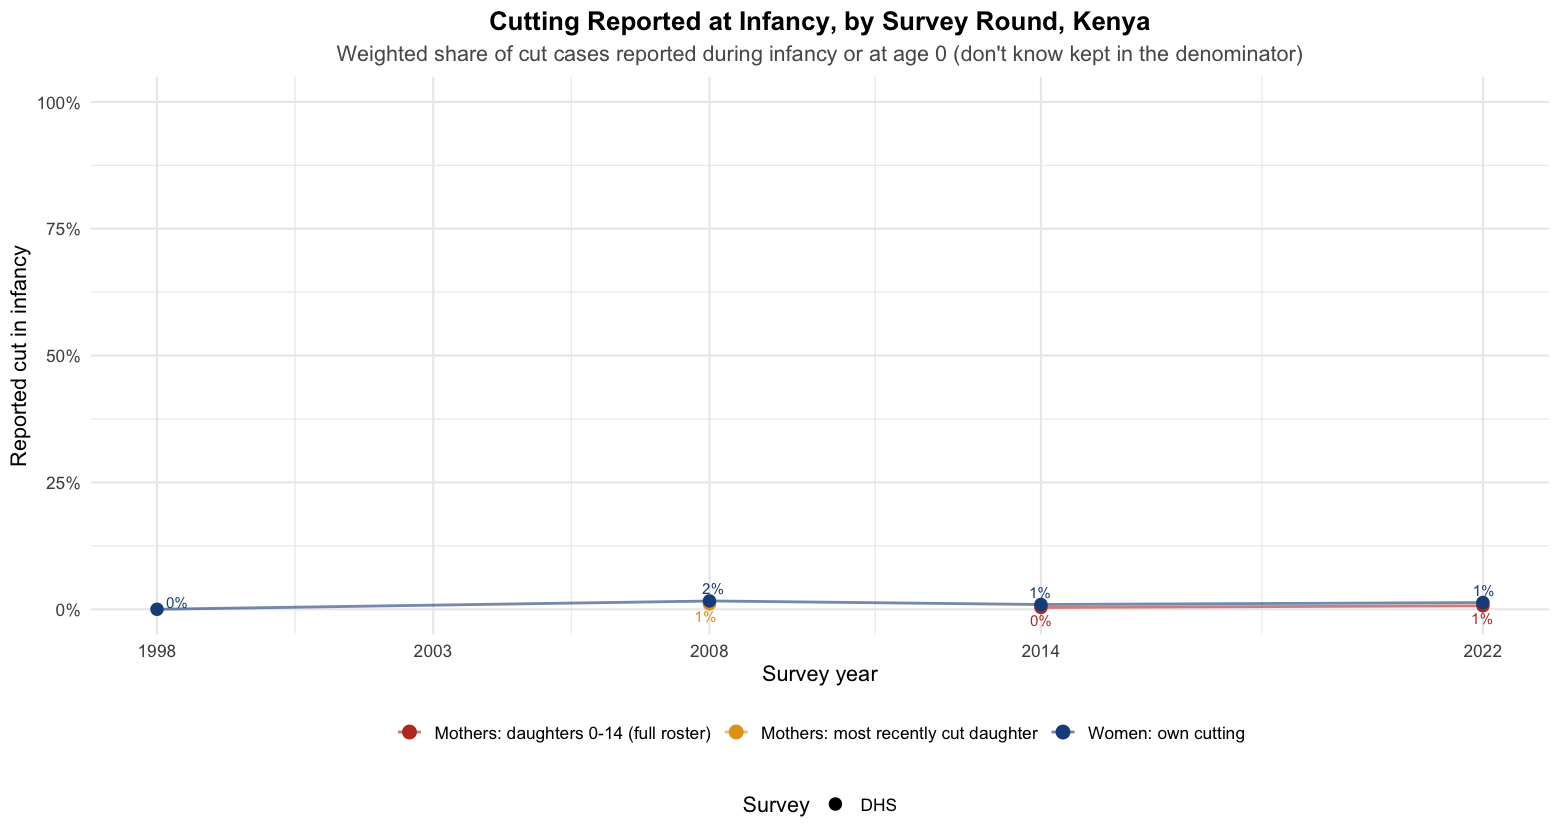

In [10]:
infancy_plot_data <- infancy_table |>
  dplyr::left_join(rounds |> dplyr::select(survey_id, survey_type, round_year), by = "survey_id")

infancy_plot <- ggplot2::ggplot(infancy_plot_data,
    ggplot2::aes(round_year, pct_infancy_weighted / 100, color = reporter, shape = survey_type)) +
  ggplot2::geom_line(ggplot2::aes(group = reporter), linewidth = 0.8, alpha = 0.6) +
  ggplot2::geom_point(size = 3.4) +
  ggrepel::geom_text_repel(ggplot2::aes(label = scales::percent(pct_infancy_weighted / 100, accuracy = 1)),
                           size = 3.2, show.legend = FALSE, seed = 1) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1), limits = c(0, 1)) +
  ggplot2::scale_x_continuous(breaks = sort(unique(rounds$round_year))) +
  ggplot2::scale_color_manual(values = c("Women: own cutting" = "#1D4E89",
                                         "Mothers: daughters 0-14 (full roster)" = "#C0392B",
                                         "Mothers: most recently cut daughter" = "#E5A11C")) +
  ggplot2::labs(title = paste("Cutting Reported at Infancy, by Survey Round,", country_name),
                subtitle = "Weighted share of cut cases reported during infancy or at age 0 (don't know kept in the denominator)",
                x = "Survey year", y = "Reported cut in infancy", color = NULL, shape = "Survey") +
  ggplot2::theme_minimal(base_size = 13) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", hjust = 0.5),
                 plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey35"),
                 legend.position = "bottom", legend.box = "vertical")

print(infancy_plot)
ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_infancy_reporting_by_round.png")),
                infancy_plot, width = 12, height = 7, dpi = 300, bg = "white")

### 5.1 Reported age at cutting, all rounds

Distribution of reported age at cutting among cut cases, by reporter and round.

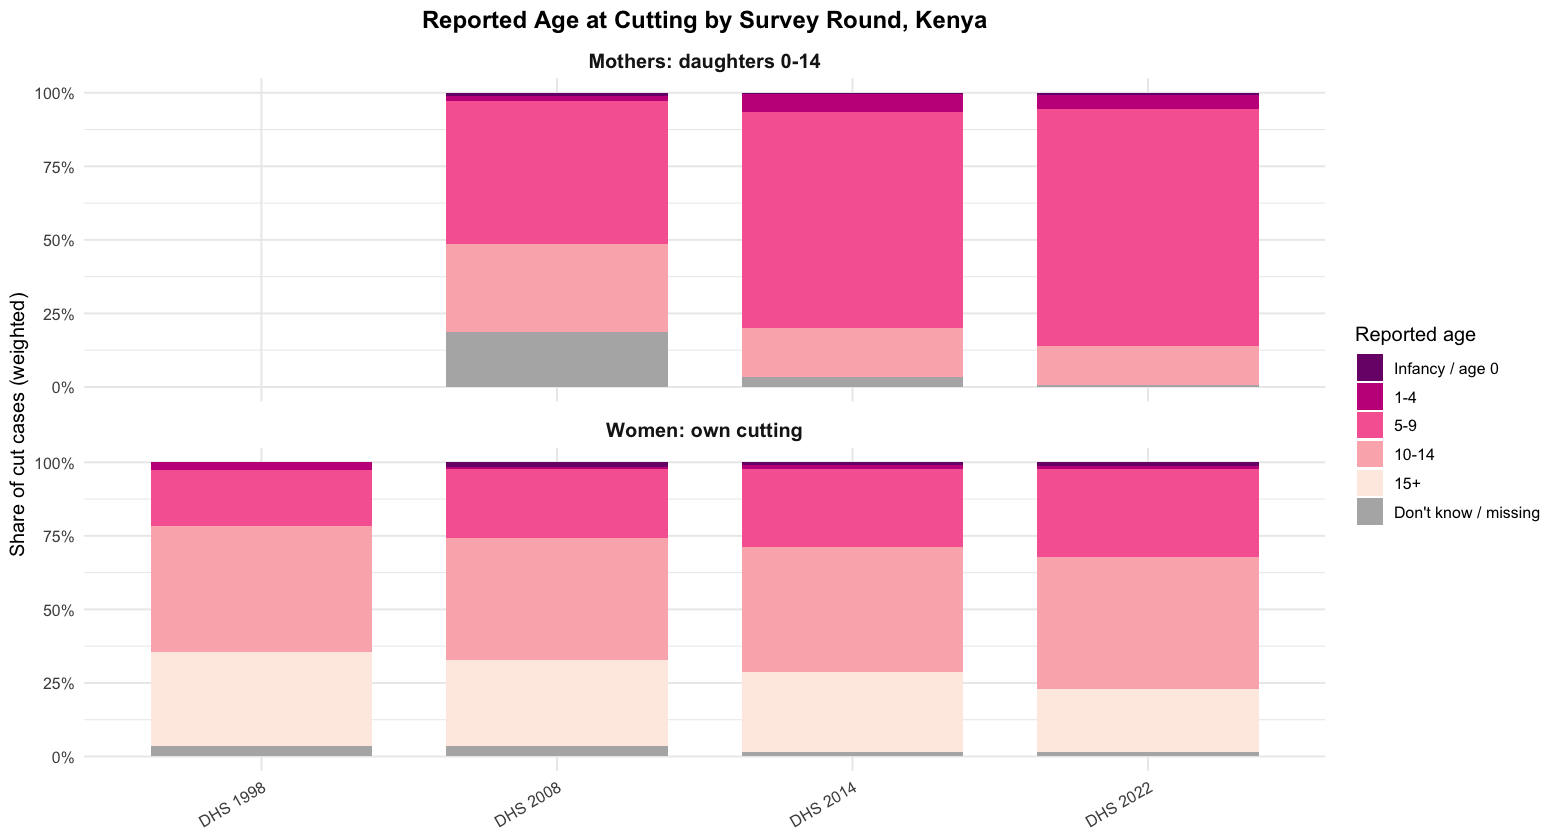

In [11]:
age_group_of <- function(age_report, age) {
  dplyr::case_when(
    age_report %in% c("during infancy", "age 0") ~ "Infancy / age 0",
    age_report == "specific age 1+" & age <= 4 ~ "1-4",
    age_report == "specific age 1+" & age <= 9 ~ "5-9",
    age_report == "specific age 1+" & age <= 14 ~ "10-14",
    age_report == "specific age 1+" ~ "15+",
    TRUE ~ "Don't know / missing"
  )
}
age_distribution <- dplyr::bind_rows(
  women |> dplyr::filter(fgm_status == 1, age_report %in% age_report_levels) |>
    dplyr::transmute(survey_id, weight, reporter = "Women: own cutting", group = age_group_of(age_report, fgm_age)),
  daughters |> dplyr::filter(daughter_status == 1) |>
    dplyr::transmute(survey_id, weight, reporter = "Mothers: daughters 0-14", group = age_group_of(age_report, daughter_age_at_cut)),
  recent_daughters |> dplyr::transmute(survey_id, weight, reporter = "Mothers: daughters 0-14",
                                       group = age_group_of(age_report, daughter_age_at_cut))
) |>
  dplyr::group_by(reporter, survey_id, group) |>
  dplyr::summarise(w = sum(weight), n = dplyr::n(), .groups = "drop_last") |>
  dplyr::mutate(share = w / sum(w)) |> dplyr::ungroup() |>
  dplyr::mutate(survey_id = factor(survey_id, levels = round_levels),
                group = factor(group, levels = c("Infancy / age 0", "1-4", "5-9", "10-14", "15+", "Don't know / missing")))

age_distribution_plot <- ggplot2::ggplot(age_distribution, ggplot2::aes(survey_id, share, fill = group)) +
  ggplot2::geom_col(width = 0.75) +
  ggplot2::facet_wrap(~reporter, ncol = 1) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1)) +
  ggplot2::scale_fill_manual(values = c("Infancy / age 0" = "#7A0177", "1-4" = "#C51B8A", "5-9" = "#F768A1",
                                        "10-14" = "#FBB4B9", "15+" = "#FEEBE2", "Don't know / missing" = "grey70")) +
  ggplot2::labs(title = paste("Reported Age at Cutting by Survey Round,", country_name),
                x = NULL, y = "Share of cut cases (weighted)", fill = "Reported age") +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", hjust = 0.5),
                 strip.text = ggplot2::element_text(face = "bold", size = 12),
                 axis.text.x = ggplot2::element_text(angle = 30, hjust = 1))
print(age_distribution_plot)
ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_age_at_cutting_distribution_by_round.png")),
                age_distribution_plot, width = 12, height = 9, dpi = 300, bg = "white")
readr::write_csv(age_distribution, file.path(output_dir, paste0(country_iso3, "_age_at_cutting_distribution_by_round.csv")))

## 6. Missing age at FGM, by current age

Percentage of cut women and girls whose age at cutting is "don't know", inconsistent or
missing, by current age, pooling every round that asked the age question (DHS 2003 women
and the most-recent-daughter records, which have no current age, are excluded).
Point size is the number of cut cases at that age.

survey_id,reporter,cut_cases,pct_missing
<fct>,<chr>,<int>,<dbl>
DHS 2014,Girls (mother's report),739,2.71
DHS 2022,Girls (mother's report),689,0.58
DHS 1998,Women (own report),2748,3.57
DHS 2008,Women (own report),2541,3.97
DHS 2014,Women (own report),4377,1.42
DHS 2022,Women (own report),4036,2.03


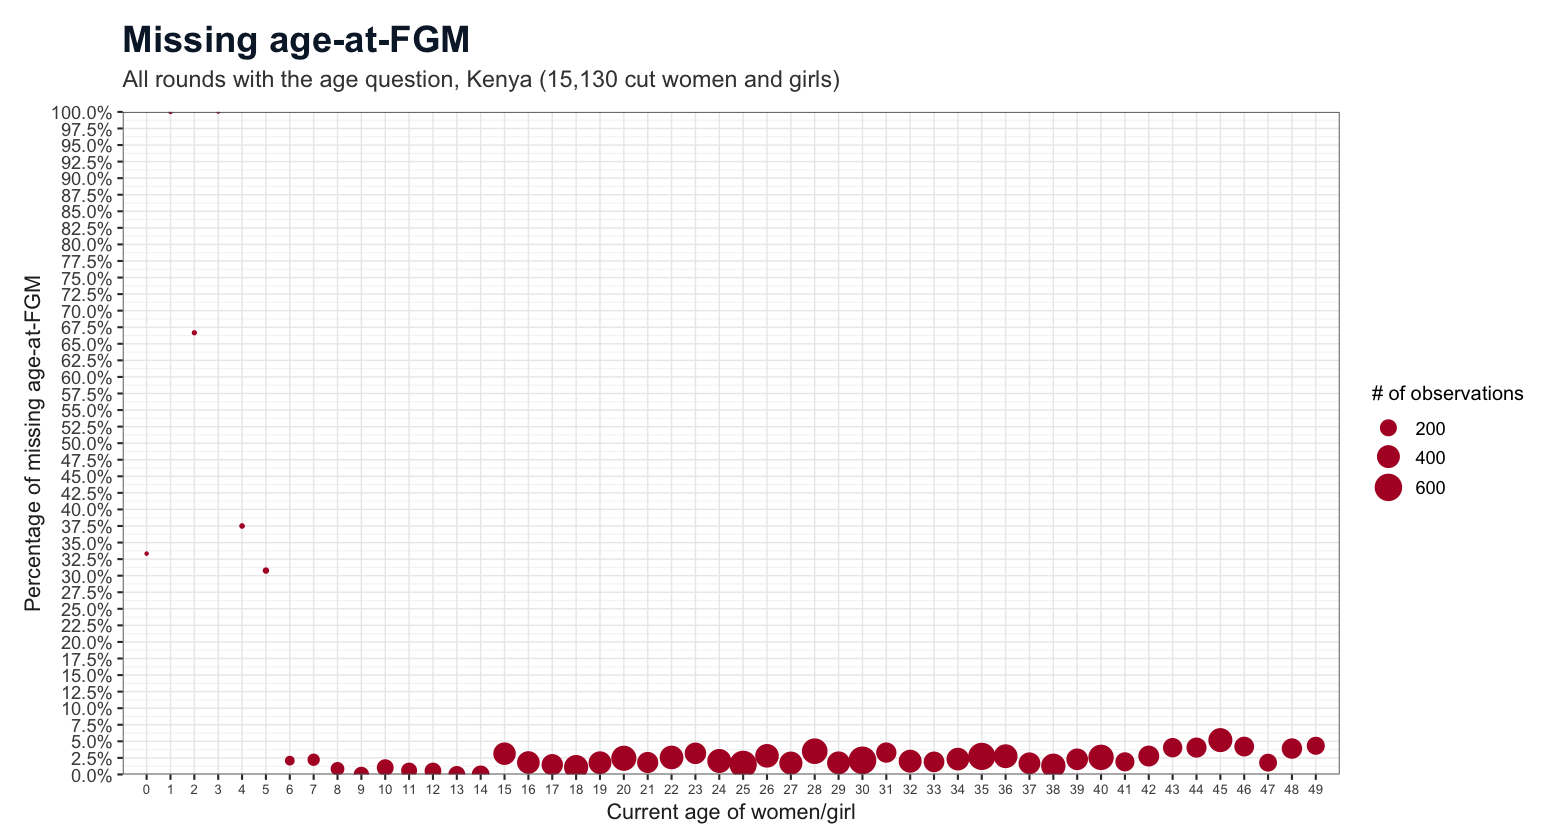

In [12]:
missing_age_data <- dplyr::bind_rows(
  women |> dplyr::filter(fgm_status == 1, age_report %in% age_report_levels) |>
    dplyr::transmute(survey_id, current_age = age, missing_age = age_report %in% c("don't know", "inconsistent", "missing"),
                     reporter = "Women (own report)"),
  daughters |> dplyr::filter(daughter_status == 1) |>
    dplyr::transmute(survey_id, current_age = daughter_age,
                     missing_age = age_report %in% c("don't know", "inconsistent", "missing"),
                     reporter = "Girls (mother's report)")
)

missing_by_age <- missing_age_data |>
  dplyr::group_by(current_age, reporter) |>
  dplyr::summarise(n = dplyr::n(), pct_missing = mean(missing_age), .groups = "drop")

# Y axis 0-10% in 2.5% steps, extended when a pooled share is higher.
y_top <- max(0.1, ceiling(max(missing_by_age$pct_missing) / 0.025) * 0.025)
missing_age_plot <- ggplot2::ggplot(missing_by_age, ggplot2::aes(current_age, pct_missing)) +
  ggplot2::geom_point(ggplot2::aes(size = n), color = "#B2182B") +
  ggplot2::scale_size_area(name = "# of observations", max_size = 7, breaks = scales::pretty_breaks(4)) +
  ggplot2::scale_x_continuous(breaks = 0:49, expand = ggplot2::expansion(add = 1)) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 0.1), breaks = seq(0, y_top, 0.025),
                              limits = c(0, y_top), expand = c(0, 0)) +
  ggplot2::labs(title = "Missing age-at-FGM",
                subtitle = paste0("All rounds with the age question, ", country_name, " (",
                                  format(nrow(missing_age_data), big.mark = ","), " cut women and girls)"),
                x = "Current age of women/girl", y = "Percentage of missing age-at-FGM") +
  ggplot2::theme_bw(base_size = 13) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 22, color = "#0B1F33"),
                 plot.subtitle = ggplot2::element_text(size = 14, color = "grey25", margin = ggplot2::margin(b = 12)),
                 axis.text.x = ggplot2::element_text(size = 8, color = "grey30"),
                 axis.text.y = ggplot2::element_text(size = 11, color = "grey30"),
                 axis.title = ggplot2::element_text(size = 13, color = "grey15"),
                 panel.grid.major = ggplot2::element_line(color = "grey92", linewidth = 0.4),
                 panel.grid.minor.x = ggplot2::element_blank(),
                 panel.grid.minor.y = ggplot2::element_line(color = "grey96", linewidth = 0.3),
                 panel.border = ggplot2::element_rect(color = "grey35", fill = NA, linewidth = 0.5),
                 legend.title = ggplot2::element_text(size = 12), legend.text = ggplot2::element_text(size = 11),
                 plot.margin = ggplot2::margin(15, 15, 10, 15))
print(missing_age_plot)
ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_missing_age_at_fgm_by_current_age.png")),
                missing_age_plot, width = 12, height = 6, dpi = 300, bg = "white")

missing_by_round <- missing_age_data |>
  dplyr::group_by(survey_id, reporter) |>
  dplyr::summarise(cut_cases = dplyr::n(), pct_missing = round(100 * mean(missing_age), 2), .groups = "drop") |>
  dplyr::mutate(survey_id = factor(survey_id, levels = round_levels)) |> dplyr::arrange(reporter, survey_id)
readr::write_csv(missing_by_age, file.path(output_dir, paste0(country_iso3, "_missing_age_at_fgm_by_current_age.csv")))
readr::write_csv(missing_by_round, file.path(output_dir, paste0(country_iso3, "_missing_age_at_fgm_by_round.csv")))
IRdisplay::display(as.data.frame(missing_by_round))

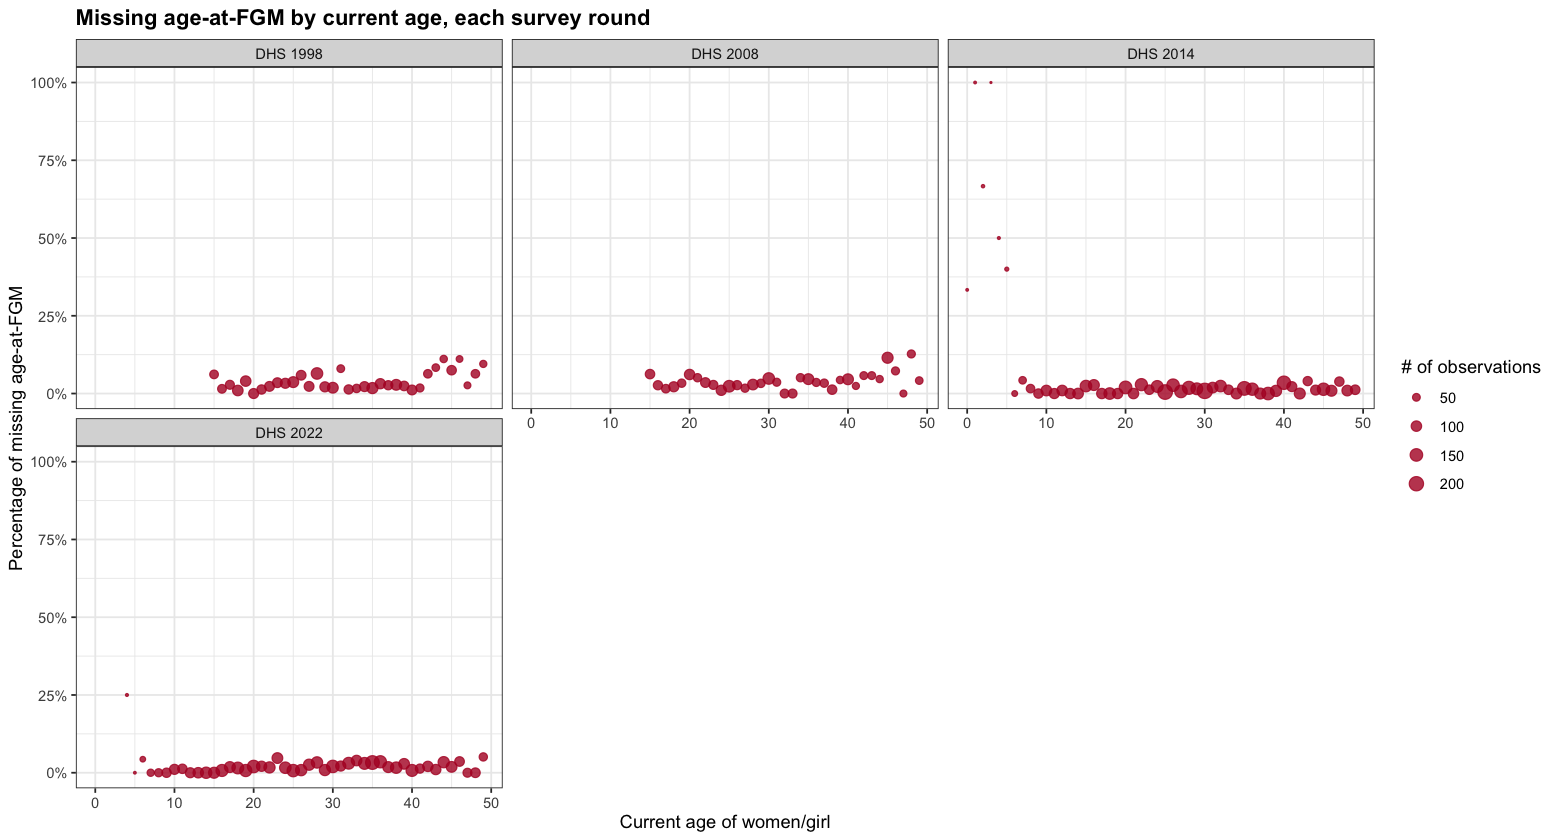

In [13]:
missing_age_round_plot <- missing_age_data |>
  dplyr::group_by(survey_id, current_age) |>
  dplyr::summarise(n = dplyr::n(), pct_missing = mean(missing_age), .groups = "drop") |>
  dplyr::mutate(survey_id = factor(survey_id, levels = round_levels)) |>
  ggplot2::ggplot(ggplot2::aes(current_age, pct_missing)) +
  ggplot2::geom_point(ggplot2::aes(size = n), color = "#B2182B", alpha = 0.8) +
  ggplot2::facet_wrap(~survey_id, ncol = 3) +
  ggplot2::scale_size_area(name = "# of observations", max_size = 4) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1)) +
  ggplot2::labs(title = "Missing age-at-FGM by current age, each survey round",
                x = "Current age of women/girl", y = "Percentage of missing age-at-FGM") +
  ggplot2::theme_bw(base_size = 11) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold"))
print(missing_age_round_plot)
ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_missing_age_at_fgm_by_current_age_each_round.png")),
                missing_age_round_plot, width = 13, height = 10, dpi = 300, bg = "white")

### 6.1 Women answering "don't know"

Two different "don't know" answers, by round. **Own status** ("don't know" whether she was
cut) was not recorded in any Kenya round; women with a missing status are excluded from
prevalence and risk. **Age at cutting** ("don't know" among
cut women) is kept in risk incidence with the age estimated as described in section 7.1.
Percentages are survey-weighted.

In [14]:
dont_know <- women |>
  dplyr::mutate(status_asked = module_asked & !status_reported %in% c("never heard (uncut)", "module not asked"),
                cut = fgm_status %in% 1) |>
  dplyr::group_by(survey_id) |>
  dplyr::summarise(
    women_asked_own_status = sum(status_asked),
    status_dont_know = sum(status_reported == "don't know"),
    status_dont_know_pct = 100 * sum(weight[status_reported == "don't know"]) / sum(weight[status_asked]),
    women_cut = sum(cut),
    age_dont_know = sum(cut & age_report %in% "don't know"),
    age_dont_know_pct = 100 * sum(weight[cut & age_report %in% "don't know"]) / sum(weight[cut]),
    age_missing_or_inconsistent = sum(cut & age_report %in% c("missing", "inconsistent")),
    .groups = "drop") |>
  dplyr::mutate(age_dont_know = dplyr::if_else(survey_id == "DHS 2003", NA_integer_, age_dont_know),
                age_dont_know_pct = dplyr::if_else(survey_id == "DHS 2003", NA_real_, age_dont_know_pct),
                survey_id = factor(survey_id, levels = round_levels)) |>
  dplyr::arrange(survey_id)
readr::write_csv(dont_know, file.path(output_dir, paste0(country_iso3, "_women_dont_know_by_round.csv")))
IRdisplay::display(as.data.frame(dont_know |> dplyr::mutate(dplyr::across(dplyr::ends_with("_pct"), ~ round(.x, 1)))))

survey_id,women_asked_own_status,status_dont_know,status_dont_know_pct,women_cut,age_dont_know,age_dont_know_pct,age_missing_or_inconsistent
<fct>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<int>
DHS 1998,7873,0,0,2748,71,2.7,27
DHS 2003,8174,0,0,2724,NA,NA,0
DHS 2008,8042,0,0,2541,99,3.5,2
DHS 2014,14294,0,0,4377,48,1.3,14
DHS 2022,16357,0,0,4036,82,1.6,0


## 7. Analysis files

The downstream notebooks read these files from `02_Data/processed/KEN/analysis/`.

- **Risk incidence** (`fgm_events`): one time-to-event record per woman or daughter; uncut
  cases are censored at current age (women capped at 49). Daughters come only from
  full-roster rounds (DHS 2014, 2022). DHS 2003 women are excluded because the survey did
  not ask age at cutting, so risk incidence uses DHS 1998, 2008–09, 2014 and 2022.
- **Prevalence**: every woman and daughter 0–14 with a known status.
- **Attitudes**: women and men who answered "continue" or "stop" ("depends" and "don't
  know" excluded, as in V1).

### 7.1 Age at cutting when it was not reported exactly

Cut cases without an exact age are neither excluded nor all placed at a single age.
Following the standard approach, their age at cutting is estimated by applying the
distribution observed among respondents in the same survey who reported an exact age.
Strict exclusion would bias risk downward, and more so in older cohorts, whose recall is
weaker.

- **"During infancy"** (DHS code 95, DHS 2008–09, 2014 and 2022): spread over ages 0–4, the "before
  age 5" group in which DHS reports place infancy. Shares come from exact reports at ages
  0–4.
- **"Don't know", missing or inconsistent ages**, including ages later than the current
  age: spread over ages 0 to the current age (women up to 49, daughters up to 14). Shares
  come from all exact reports.
- **Same survey and birth cohort.** Exact reporters come from the same survey and birth
  cohort, because recall differs by cohort; the whole survey is used when the cohort has
  fewer than 30 exact reporters in the relevant age range.
- **No randomness.** Each such case is split into fractional records whose shares sum to
  one; each keeps the respondent's survey weight multiplied by its share (`age_share`), so
  the estimates are deterministic and reproducible.

DHS 1998 has no separate infancy code; its answers are exact ages. Reported ages of 0 are
kept as age 0.

In [15]:
event_fields <- c("id", "person_id", "record_type", "survey_id", "survey_type", "round_year", "region", "county", "cluster",
                  "strata", "urban_rural", "weight", "age", "birth_year", "birth_cohort", "ethnicity", "education",
                  "religion", "wealth", "fgm_event", "time", "age_share", "age_source")
min_exact_reporters <- 30L

# One harmonized table of cut and uncut histories, before any age estimation.
histories <- dplyr::bind_rows(
  women |> dplyr::filter(!is.na(fgm_status), survey_id != "DHS 2003") |>
    dplyr::transmute(person_id = resp_id, record_type = "self", survey_id, survey_type, round_year, region, county, cluster,
                     strata, urban_rural, weight, age, birth_year, birth_cohort, ethnicity, education, religion,
                     wealth, fgm_event = fgm_status, age_cut = fgm_age, age_report, max_cut_age = max_age_years),
  daughters |>
    dplyr::transmute(person_id = daughter_id, record_type = "daughter", survey_id, survey_type, round_year, region,
                     county, cluster, strata, urban_rural, weight, age = daughter_age, birth_year, birth_cohort, ethnicity,
                     education, religion, wealth, fgm_event = daughter_status, age_cut = daughter_age_at_cut,
                     age_report, max_cut_age = max_daughter_age)
) |>
  dplyr::filter(!is.na(birth_cohort), !is.na(region)) |>
  dplyr::mutate(age_source = dplyr::case_when(
    fgm_event == 0 ~ "not cut",
    # DHS code 95 is a vague answer; MICS 2011 records infancy as "00" (the first year of
    # life), which is its only age-0 code, so it is kept as an exact age 0.
    age_report == "during infancy" & survey_type == "DHS" ~ "during infancy (spread over 0-4)",
    (age_report %in% c("age 0", "specific age 1+") | (age_report == "during infancy" & survey_type == "MICS")) &
      age_cut <= age ~ "exact age reported",
    TRUE ~ "unknown age (spread over 0 to current age)"))

exact_reports <- histories |> dplyr::filter(age_source == "exact age reported")

# Spread each case over its admissible ages using exact reporters of the same survey
# (and birth cohort when it has enough exact reporters in that age range).
spread_age_at_cutting <- function(cases, upper_age) {
  if (!nrow(cases)) return(tibble::tibble())
  cohort_counts <- exact_reports |> dplyr::group_by(record_type, survey_id, birth_cohort, age_cut) |>
    dplyr::summarise(w_cohort = sum(weight), n_cohort = dplyr::n(), .groups = "drop")
  survey_counts <- exact_reports |> dplyr::group_by(record_type, survey_id, age_cut) |>
    dplyr::summarise(w_survey = sum(weight), n_survey = dplyr::n(), .groups = "drop")
  cases |>
    dplyr::mutate(top_age = as.integer(pmin(upper_age, floor(age), max_cut_age))) |>
    tidyr::uncount(top_age + 1L, .id = "k") |>
    dplyr::mutate(age_cut = k - 1) |>
    dplyr::left_join(cohort_counts, by = c("record_type", "survey_id", "birth_cohort", "age_cut")) |>
    dplyr::left_join(survey_counts, by = c("record_type", "survey_id", "age_cut")) |>
    dplyr::mutate(dplyr::across(c(w_cohort, n_cohort, w_survey, n_survey), ~ tidyr::replace_na(.x, 0))) |>
    dplyr::group_by(person_id) |>
    dplyr::mutate(source_level = dplyr::case_when(sum(n_cohort) >= min_exact_reporters ~ "cohort",
                                                  sum(n_survey) > 0 ~ "survey", TRUE ~ "uniform"),
                  age_share = dplyr::case_when(source_level == "cohort" ~ w_cohort / sum(w_cohort),
                                               source_level == "survey" ~ w_survey / sum(w_survey),
                                               TRUE ~ 1 / dplyr::n())) |>
    dplyr::ungroup() |>
    dplyr::filter(age_share > 0) |>
    dplyr::select(-k, -top_age, -w_cohort, -n_cohort, -w_survey, -n_survey)
}

spread_infancy <- spread_age_at_cutting(histories |> dplyr::filter(age_source == "during infancy (spread over 0-4)"), 4L)
spread_unknown <- spread_age_at_cutting(histories |> dplyr::filter(age_source == "unknown age (spread over 0 to current age)"), 49L)
stopifnot(all(abs(tapply(spread_infancy$age_share, spread_infancy$person_id, sum) - 1) < 1e-9),
          all(abs(tapply(spread_unknown$age_share, spread_unknown$person_id, sum) - 1) < 1e-9))

fgm_events <- dplyr::bind_rows(
  histories |> dplyr::filter(age_source %in% c("not cut", "exact age reported")) |>
    dplyr::mutate(age_share = 1, source_level = NA_character_),
  spread_infancy, spread_unknown
) |>
  dplyr::mutate(
    time = dplyr::if_else(fgm_event == 1, age_cut, pmin(age, dplyr::if_else(record_type == "self", max_age_years, age))),
    weight = weight * age_share,
    id = dplyr::if_else(age_share < 1, paste0(person_id, "-a", age_cut), person_id)
  ) |>
  dplyr::select(dplyr::all_of(event_fields), source_level)
stopifnot(!anyDuplicated(fgm_events$id), all(fgm_events$time >= 0), all(fgm_events$time <= fgm_events$age))

age_source_summary <- histories |>
  dplyr::filter(fgm_event == 1) |>
  dplyr::count(record_type, survey_id, age_source) |>
  tidyr::pivot_wider(names_from = age_source, values_from = n, values_fill = 0) |>
  dplyr::left_join(dplyr::bind_rows(spread_infancy, spread_unknown) |>
                     dplyr::distinct(person_id, record_type, survey_id, source_level) |>
                     dplyr::count(record_type, survey_id, source_level) |>
                     tidyr::pivot_wider(names_from = source_level, values_from = n, values_fill = 0,
                                        names_prefix = "distribution from: "),
                   by = c("record_type", "survey_id")) |>
  dplyr::mutate(survey_id = factor(survey_id, levels = round_levels)) |>
  dplyr::arrange(dplyr::desc(record_type), survey_id)
readr::write_csv(age_source_summary, file.path(output_dir, paste0(country_iso3, "_risk_age_at_cutting_sources.csv")))
cat("Cut cases by how age at cutting enters risk incidence (DHS 2003 women excluded: age not asked)
")
IRdisplay::display(as.data.frame(age_source_summary))


prevalence_self <- women |> dplyr::filter(!is.na(fgm_status)) |>
  dplyr::transmute(id = resp_id, survey_id, survey_type, round_year, region, county, cluster, strata, urban_rural, weight,
                   age, birth_year, birth_cohort, ethnicity, education, religion, wealth, fgm_self = fgm_status)
prevalence_daughter <- daughters |>
  dplyr::transmute(id = daughter_id, mother_id = resp_id, survey_id, survey_type, round_year, region, county, cluster, strata,
                   urban_rural, weight, age = daughter_age, birth_year, birth_cohort, ethnicity, education,
                   religion, wealth, fgm_daughter = daughter_status)
attitude_women <- women |> dplyr::filter(!is.na(supports_continuation)) |>
  dplyr::transmute(id = resp_id, survey_id, survey_type, round_year, region, county, cluster, strata, urban_rural, weight,
                   age, birth_year, birth_cohort, own_status = fgm_status, education, religion, wealth, ethnicity,
                   supports_continuation)
attitude_men <- men |> dplyr::filter(!is.na(supports_continuation)) |>
  dplyr::transmute(id = resp_id, survey_id, survey_type, round_year, region, county, cluster, strata, urban_rural, weight,
                   age, education, religion, wealth, ethnicity, supports_continuation)

analysis_files <- list(fgm_events = fgm_events, prevalence_self = prevalence_self,
                       prevalence_daughter = prevalence_daughter, attitude_women = attitude_women,
                       attitude_men = attitude_men)
for (nm in names(analysis_files)) {
  saveRDS(analysis_files[[nm]], file.path(analysis_dir, paste0(country_iso3, "_", nm, ".rds")))
}
IRdisplay::display(as.data.frame(tibble::tibble(
  file = paste0(country_iso3, "_", names(analysis_files), ".rds"),
  records = vapply(analysis_files, nrow, integer(1)),
  rounds = vapply(analysis_files, function(d) paste(sort(unique(d$survey_id)), collapse = ", "), character(1)))))

Cut cases by how age at cutting enters risk incidence (DHS 2003 women excluded: age not asked)


record_type,survey_id,exact age reported,unknown age (spread over 0 to current age),during infancy (spread over 0-4),distribution from: cohort,distribution from: survey
<chr>,<fct>,<int>,<int>,<int>,<int>,<int>
self,DHS 1998,2650,98,0,98,0
self,DHS 2008,2391,101,49,101,49
self,DHS 2014,4249,62,66,61,67
self,DHS 2022,3924,82,30,82,30
daughter,DHS 2014,719,20,0,10,10
daughter,DHS 2022,685,4,0,3,1


file,records,rounds
<chr>,<int>,<chr>
KEN_fgm_events.rds,82110,"DHS 1998, DHS 2008, DHS 2014, DHS 2022"
KEN_prevalence_self.rds,56116,"DHS 1998, DHS 2003, DHS 2008, DHS 2014, DHS 2022"
KEN_prevalence_daughter.rds,26714,"DHS 2014, DHS 2022"
KEN_attitude_women.rds,44886,"DHS 1998, DHS 2008, DHS 2014, DHS 2022"
KEN_attitude_men.rds,24385,"DHS 2014, DHS 2022"


## 7A. Check against the official DHS reports

Before modelling, the harmonised data must reproduce the official DHS figures (DHS Program API,
national values). Women's prevalence and attitudes match the official tables because no Kenya
round recorded a "don't know" own status. The official attitude figure keeps "depends" and
"don't know" answers in the denominator, so it is compared with the share of all answers.

In [16]:
options(survey.lonely.psu = "adjust")
official <- tibble::tribble(
  ~survey_id, ~indicator, ~official,
  "DHS 1998", "Women 15-49 circumcised", 37.6, "DHS 2003", "Women 15-49 circumcised", 32.2,
  "DHS 2008", "Women 15-49 circumcised", 27.1, "DHS 2014", "Women 15-49 circumcised", 21.0,
  "DHS 2022", "Women 15-49 circumcised", 14.8,
  "DHS 2008", "Heard of FGM", 96.1, "DHS 2014", "Heard of FGM", 96.8, "DHS 2022", "Heard of FGM", 96.9,
  "DHS 2014", "Girls 0-14 circumcised", 2.8, "DHS 2022", "Girls 0-14 circumcised", 1.6,
  "DHS 1998", "Women: support continuation (all answers)", 19.8, "DHS 2008", "Women: support continuation (all answers)", 9.8,
  "DHS 2014", "Women: support continuation (all answers)", 6.2, "DHS 2022", "Women: support continuation (all answers)", 4.3,
  "DHS 2014", "Men: support continuation (all answers)", 9.3, "DHS 2022", "Men: support continuation (all answers)", 4.8)
ours_one <- function(d, var) {
  d <- d |> dplyr::filter(!is.na(.data[[var]]))
  if (!nrow(d)) return(NA_real_)
  des <- survey::svydesign(ids = ~cluster, strata = ~strata, weights = ~weight, data = d, nest = TRUE)
  round(100 * as.numeric(stats::coef(survey::svymean(stats::as.formula(paste0("~", var)), des))), 1)
}
support_all <- function(d) d |> dplyr::mutate(support_all = dplyr::if_else(!is.na(attitude_answer), as.numeric(attitude_answer == "continued"), NA_real_))
ours <- dplyr::bind_rows(lapply(c("DHS 1998", "DHS 2003", "DHS 2008", "DHS 2014", "DHS 2022"), function(s) {
  w <- women |> dplyr::filter(survey_id == s) |> support_all() |>
    dplyr::mutate(heard_any = dplyr::if_else(module_asked & !is.na(fgm_heard), as.numeric(fgm_heard %in% TRUE), NA_real_))
  d <- daughters |> dplyr::filter(survey_id == s)
  m <- men |> dplyr::filter(survey_id == s, fgm_heard) |> support_all()
  tibble::tibble(survey_id = s,
                 indicator = c("Women 15-49 circumcised", "Heard of FGM", "Girls 0-14 circumcised",
                               "Women: support continuation (all answers)", "Men: support continuation (all answers)"),
                 ours = c(ours_one(w, "fgm_status"), ours_one(w, "heard_any"),
                          if (nrow(d)) ours_one(d, "daughter_status") else NA_real_, ours_one(w, "support_all"),
                          if (nrow(m)) ours_one(m, "support_all") else NA_real_))
}))
official_check <- official |> dplyr::left_join(ours, by = c("survey_id", "indicator")) |>
  dplyr::mutate(difference = round(ours - official, 1))
readr::write_csv(official_check, file.path(output_dir, paste0(country_iso3, "_official_report_check.csv")))
IRdisplay::display(as.data.frame(official_check))
stopifnot(all(abs(official_check$difference) <= 0.2))

survey_id,indicator,official,ours,difference
<chr>,<chr>,<dbl>,<dbl>,<dbl>
DHS 1998,Women 15-49 circumcised,37.6,37.7,0.1
DHS 2003,Women 15-49 circumcised,32.2,32.2,0.0
DHS 2008,Women 15-49 circumcised,27.1,27.1,0.0
DHS 2014,Women 15-49 circumcised,21.0,21.0,0.0
DHS 2022,Women 15-49 circumcised,14.8,14.8,0.0
DHS 2008,Heard of FGM,96.1,96.1,0.0
DHS 2014,Heard of FGM,96.8,96.8,0.0
DHS 2022,Heard of FGM,96.9,96.9,0.0
DHS 2014,Girls 0-14 circumcised,2.8,2.9,0.1


## 7B. Subnational MICS surveys

Kenya has no national MICS. Five MICS surveys cover single areas: Mombasa informal settlements
(2009, MICS4), Nyanza province (2011, MICS4) and Bungoma, Kakamega and Turkana counties (2013–14,
MICS5). They are harmonised with the DHS definitions (never heard of FGM → not cut; support =
"continued" among "continued" or "discontinued") and compared with DHS for the same area in the
prevalence (8A), risk (15C) and attitude (Part D) notebooks. MICS4 did not ask women their own
age at cutting. The MICS releases have no stratum variable, so the cluster is the PSU and
urban/rural the stratum.

In [17]:
source(file.path(project_root, "00_Pipeline", "mics_core.R"))
mics_women <- harmonize_mics(file.path(project_root, "02_Data", "raw", "kenya_FGM_Data", "extracted", "MICS"))
saveRDS(mics_women, file.path(harmonized_dir, paste0(country_iso3, "_mics_subnational_women.rds")))
mics_records <- mics_women |> dplyr::group_by(survey = source) |>
  dplyr::summarise(women = dplyr::n(), status_known = sum(!is.na(fgm_status)), women_cut = sum(fgm_status %in% 1),
                   cut_with_age = sum(!is.na(fgm_age)), attitude_continue_or_stop = sum(!is.na(supports_continuation)), .groups = "drop")
readr::write_csv(mics_records, file.path(output_dir, paste0(country_iso3, "_mics_subnational_records.csv")))
IRdisplay::display(as.data.frame(mics_records))

survey,women,status_known,women_cut,cut_with_age,attitude_continue_or_stop
<chr>,<int>,<int>,<int>,<int>,<int>
MICS 2009 Mombasa informal settlements,821,821,102,0,720
MICS 2011 Nyanza,5908,5901,2174,0,4293
MICS 2013-14 Bungoma,1213,1213,38,36,1034
MICS 2013-14 Kakamega,998,998,11,10,819
MICS 2013-14 Turkana,1104,1101,31,24,425


## 8. Summary of results

Generated from the tables saved by this notebook (`03_Outputs/KEN/EDA/`). Counts are unweighted; percentages are survey-weighted.

### 8.1 Records and prevalence by survey round

| Survey | Women interviewed | Women with known status | Never heard (counted uncut) | Women cut | Prevalence, women 15–49 % (95% CI) | Daughters 0–14 | Daughters cut | Prevalence, girls 0–14 % (95% CI) | Men with attitude answer |
|---|---:|---:|---:|---:|---|---:|---:|---|---:|
| DHS 1998 | 7,881 | 7,873 | 0 | 2,748 | 37.7 (35.8–39.5) | – | – | – | – |
| DHS 2003 | 8,195 | 8,174 | 0 | 2,724 | 32.2 (29.6–34.9) | – | – | – | – |
| DHS 2008 | 8,444 | 8,433 | 395 | 2,541 | 27.1 (23.4–30.8) | – | – | – | – |
| DHS 2014 | 31,079 | 14,734 | 445 | 4,377 | 21.0 (19.7–22.2) | 13,189 | 739 | 2.9 (2.5–3.3) | 11,507 |
| DHS 2022 | 32,156 | 16,902 | 545 | 4,036 | 14.8 (14.0–15.7) | 13,525 | 689 | 1.6 (1.4–1.8) | 12,878 |
| **Total** | 87,755 | 56,116 | 1,385 | 16,426 | – | 26,714 | 1,428 | – | 24,385 |

### 8.2 Cutting declared at infancy, by survey round

"During infancy" is the explicit answer code (DHS code 95, DHS 2008–09, 2014 and 2022); DHS 1998 has no such code. The infancy percentage counts infancy answers and reported ages of 0, and keeps "don't know" answers in the denominator. In Kenya very few women report cutting in infancy.

| Survey | Women cut | Women: "during infancy" | Women: age 0 | Women: age unknown | Women cut in infancy, % (weighted) | Daughters cut | Daughters: "during infancy" or age 0 | Daughters: age unknown | Daughters cut in infancy, % (weighted) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| DHS 1998 | 2,748 | 0 | 0 | 98 | 0.0 | – | – | – | – |
| DHS 2003 | 2,724 | not asked | not asked | not asked | – | – | – | – | – |
| DHS 2008 | 2,541 | 49 | 3 | 101 | 1.6 | 524 † | 7 † | 62 † | 1.1 † |
| DHS 2014 | 4,377 | 66 | 0 | 62 | 0.9 | 739 | 3 | 20 | 0.4 |
| DHS 2022 | 4,036 | 30 | 1 | 82 | 1.3 | 689 | 3 | 4 | 0.7 |
| **Total** | 16,426 | 145 | 4 | 343 | – | 1,952 | 13 | 86 | – |

† DHS 2008–09 records age at cutting only for the most recently cut daughter, so its daughter figures cover that daughter only. DHS 2003 did not ask women their own age at cutting.

### 8.3 Women answering "don't know", by survey round

| Survey | Women asked own status | Own status "don't know" (weighted %) | Women cut | Age at cutting "don't know" (weighted %) | Age missing or inconsistent |
|---|---:|---:|---:|---:|---:|
| DHS 1998 | 7,873 | not an answer option | 2,748 | 71 (2.7%) | 27 |
| DHS 2003 | 8,174 | not an answer option | 2,724 | age not asked | 0 |
| DHS 2008 | 8,042 | not an answer option | 2,541 | 99 (3.5%) | 2 |
| DHS 2014 | 14,294 | not an answer option | 4,377 | 48 (1.3%) | 14 |
| DHS 2022 | 16,357 | not an answer option | 4,036 | 82 (1.6%) | 0 |
| **Total** | 54,740 | 0 | 16,426 | 300 | 43 |

Women with an unknown own status are excluded from prevalence and risk; cut women with an unknown age at cutting are kept in risk incidence with an estimated age (section 7.1).

## 9. Notes for interpretation

- Cohort trends pool rounds by birth cohort. A cohort observed in several rounds is
  reported at different ages; time-to-event methods use each record only up to its
  observed age.
- Ethnicity is the respondent's own in every round. Wealth is unavailable in DHS 1998; models
  keep it as an "unknown" category for that round.
- DHS 1998 did not sample North Eastern province; DHS 2003 has no age at cutting or attitude
  question; men's attitudes are available only from DHS 2014 and 2022.
- Reported age at cutting is retrospective. In Kenya most cutting is reported at ages 5–14,
  so girls aged 0–14 are observed before much of their risk; daughters' estimates cover early
  ages only.